In [1]:
!pip -q install transformers

In [2]:
import torch
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from IPython.display import HTML, display
from transformers import pipeline

device = 0 if torch.cuda.is_available() else -1
ner = pipeline("ner", model="dslim/bert-base-NER", aggregation_strategy="simple", device=device)

config.json:   0%|          | 0.00/829 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  433MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dslim/bert-base-NER
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.bias   | UNEXPECTED |  | 
bert.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/59.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

In [3]:
text = ("Sundar Pichai, the CEO of Google, met Narendra Modi in New Delhi on Monday to discuss "
        "investments in India. Microsoft and Infosys also announced a partnership in Bengaluru, "
        "while Elon Musk visited the Indian Institute of Technology in Mumbai.")
entities = ner(text)
df = pd.DataFrame(entities)[["word", "entity_group", "score", "start", "end"]]
df["score"] = df["score"].round(3)
display(df)

,word,entity_group,score,start,end
0,Sundar Pichai,PER,0.995,0,13
1,Google,ORG,0.999,26,32
2,Na,PER,0.999,38,40
3,##ren,PER,0.865,40,43
4,##dra Modi,PER,0.868,43,51
5,New Delhi,LOC,1.000,55,64
6,India,LOC,0.999,101,106
7,Microsoft,ORG,0.999,108,117
8,In,ORG,0.999,122,124
9,##fosys,ORG,0.998,124,129


In [4]:
# Highlight entities in the text
colors = {"PER": "#ffd6a5", "ORG": "#caffbf", "LOC": "#9bf6ff", "MISC": "#ffc6ff"}

def highlight(text, ents):
    out, last = "", 0
    for e in sorted(ents, key=lambda x: x["start"]):
        out += text[last:e["start"]]
        out += (f'<mark style="background:{colors.get(e["entity_group"], "#ddd")};padding:2px 5px;border-radius:4px">'
                f'{text[e["start"]:e["end"]]} <b style="font-size:10px">{e["entity_group"]}</b></mark>')
        last = e["end"]
    return out + text[last:]

display(HTML("<div style='font-size:16px;line-height:2'>" + highlight(text, entities) + "</div>"))

Entity counts: {'PER': 5, 'ORG': 6, 'LOC': 4}


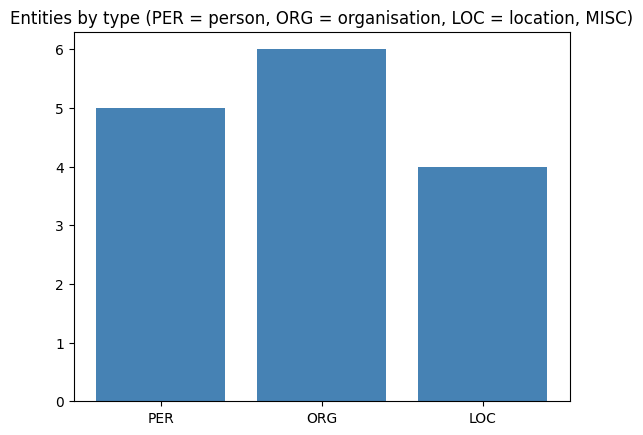

PER  : ['Sundar Pichai', 'Na', '##ren', '##dra Modi', '##on Musk']
ORG  : ['Google', 'Microsoft', 'In', '##fosys', 'El', 'Indian Institute of Technology']
LOC  : ['New Delhi', 'India', 'Bengaluru', 'Mumbai']


In [5]:
# Entity statistics
counts = Counter(e["entity_group"] for e in entities)
print("Entity counts:", dict(counts))
plt.bar(counts.keys(), counts.values(), color="steelblue")
plt.title("Entities by type (PER = person, ORG = organisation, LOC = location, MISC)")
plt.show()

grouped = {}
for e in entities:
    grouped.setdefault(e["entity_group"], []).append(e["word"])
for k, v in grouped.items(): print(f"{k:5s}:", v)

In [6]:
# Token-level (BIO) predictions without aggregation
raw_ner = pipeline("ner", model="dslim/bert-base-NER", device=device)
short = "Rahul works at Amazon in Hyderabad."
for t in raw_ner(short):
    print(f"{t['word']:12s} {t['entity']:8s} {t['score']:.3f}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dslim/bert-base-NER
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.bias   | UNEXPECTED |  | 
bert.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Ra           B-PER    0.999
##hul        B-PER    0.949
Amazon       B-LOC    0.999
Hyderabad    B-LOC    0.999


In [7]:
# Try several sentences
tests = ["Apple opened a new store in Paris last week.",
         "Virat Kohli scored a century against Australia at Melbourne.",
         "The United Nations met in Geneva to talk about climate change."]
for s in tests:
    print(s)
    print("  ->", [(e["word"], e["entity_group"]) for e in ner(s)])

Apple opened a new store in Paris last week.
  -> [('Apple', 'ORG'), ('Paris', 'LOC')]
Virat Kohli scored a century against Australia at Melbourne.
  -> [('V', 'PER'), ('##ira', 'PER'), ('##t Kohli', 'PER'), ('Australia', 'LOC'), ('Melbourne', 'LOC')]
The United Nations met in Geneva to talk about climate change.
  -> [('United Nations', 'ORG'), ('Geneva', 'LOC')]
